In [1]:
import pandas as pd
import numpy as np
from dateutil.relativedelta import relativedelta

In [2]:
df_full = pd.read_csv('../CSVs/04_malaria_data_cleaned.csv').drop(columns=['rainfall', 'prev_month_rainfall', 'u5_rdt_positive', 'u5_rdt_negative', 'u5_tpr'])
df_full['visit_month'] = pd.to_datetime(df_full['visit_month'])
nasa_raw = pd.read_csv('../CSVs/06_climate_data_aggregated.csv')

In [3]:
num = []
for x in df_full['village_code'].unique():
    num.append(len(df_full[df_full['village_code'] == x]))
np.mean(num)

np.float64(21.079787234042552)

In [4]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
          'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec', 'Annual']

nasa_raw.columns = ['param', 'year'] + months

nasa_long = nasa_raw.melt(
    id_vars=['param', 'year'],
    value_vars=months,
    var_name='month',
    value_name='value'
)

nasa_long = nasa_long[nasa_long['month'] != 'Annual']

nasa_long['month_num'] = pd.to_datetime(nasa_long['month'], format='%b').dt.month

nasa_long['visit_month'] = pd.to_datetime(dict(year=nasa_long['year'], month=nasa_long['month_num'], day=1))

nasa_wide = nasa_long.pivot_table(
    index='visit_month',
    columns='param',
    values='value',
    aggfunc='first'
).reset_index()

nasa_wide.columns.name = None

In [5]:
# Merge climate data into main malaria dataframe based on 'visit_month'
df_full = df_full.merge(
    nasa_wide,
    on='visit_month',
    how='left'  # Ensures all rows in df_full are preserved, even if some dates are missing in nasa_wide
)

In [6]:
nasa_wide

,visit_month,PRECTOTCORR,PRECTOTCORR_SUM,RH2M,T2M,T2M_MAX,T2M_MIN,T2M_RANGE
0,2014-01-01,8.71,269.90,86.58,26.46,33.31,20.09,7.26
1,2014-02-01,10.93,306.06,87.27,26.03,31.91,20.78,7.31
2,2014-03-01,1.62,50.24,83.32,26.31,32.91,19.95,8.90
3,2014-04-01,2.77,83.01,75.40,25.02,36.44,16.90,11.56
4,2014-05-01,1.30,40.16,70.84,24.29,35.54,16.18,13.39
...,...,...,...,...,...,...,...,...
91,2021-08-01,0.32,10.03,65.20,23.60,37.98,12.60,15.39
92,2021-09-01,0.65,19.57,60.62,26.11,40.45,14.82,15.55
93,2021-10-01,0.36,11.10,54.91,28.41,44.99,16.74,16.24
94,2021-11-01,0.77,23.14,54.91,30.98,46.34,18.09,16.53


In [7]:
print(nasa_wide[nasa_wide['visit_month'] == '2017-01-01'][['T2M', 'RH2M', 'PRECTOTCORR']])

      T2M   RH2M  PRECTOTCORR
36  27.23  85.07         7.11


In [8]:
df_full.columns

Index(['village_code', 'visit_month', 'spray_status', 'u5_residents',
       'total_residents', 'u5_incidence', 'clinic_tests', 'total_rdts',
       'u5_total_rdts', 'avg_distance_to_health_facility_km',
       'incidence_per_1000', 'positivity_rate', 'dist_missing', 'PRECTOTCORR',
       'PRECTOTCORR_SUM', 'RH2M', 'T2M', 'T2M_MAX', 'T2M_MIN', 'T2M_RANGE'],
      dtype='str')

In [10]:
climate_params = ['PRECTOTCORR', 'PRECTOTCORR_SUM', 'RH2M', 'T2M',
                     'T2M_MAX', 'T2M_MIN', 'T2M_RANGE']
for lag in [1, 2, 3, 4]:
    prefix = 'prev' if lag == 1 else f'prev{lag}'
    shifted = nasa_wide.copy()
    shifted['visit_month'] = shifted['visit_month'] + pd.DateOffset(months=lag)
    shifted = shifted.rename(columns={p: f'{prefix}_{p}' for p in climate_params})
    df_full = df_full.merge(shifted, on='visit_month', how='left')

lag_cols = [f'{p}_{param}' for param in climate_params for p in ['prev', 'prev2', 'prev3', 'prev4']]
df_full = df_full[[c for c in df_full.columns if c not in lag_cols] + lag_cols]
print('Missing climate lags:', df_full[lag_cols].isna().sum().sum())

Missing climate lags: 0


In [11]:
## Part II. Adding prev_incidence_per_1000

In [12]:
prev = df_full[['village_code', 'visit_month', 'incidence_per_1000', 'u5_incidence']].copy()
prev['visit_month'] = prev['visit_month'] + pd.DateOffset(months=1)
prev = prev.rename(columns={'incidence_per_1000': 'prev_incidence_per_1000',
                            'u5_incidence': 'prev_u5_incidence_per_1000'})
df_full = df_full.merge(prev, on=['village_code', 'visit_month'], how='left')

In [13]:
df_full.to_csv('../CSVs/07_climate_malaria_data_integrated.csv', index=False)

In [14]:
df_full = df_full[df_full['prev_incidence_per_1000'].notna()]
df_full = df_full[df_full['prev_u5_incidence_per_1000'].notna()]
# I really don't have a way of filling this like I did with the climate data. Plus it's just 4% of the data so it's fine

In [15]:
df_full.isna().any().sum()
# DONE!!

np.int64(1)

In [16]:
df_full.isna().any()

village_code                          False
visit_month                           False
spray_status                          False
u5_residents                          False
total_residents                       False
u5_incidence                          False
clinic_tests                          False
total_rdts                            False
u5_total_rdts                         False
avg_distance_to_health_facility_km     True
incidence_per_1000                    False
positivity_rate                       False
dist_missing                          False
PRECTOTCORR                           False
PRECTOTCORR_SUM                       False
RH2M                                  False
T2M                                   False
T2M_MAX                               False
T2M_MIN                               False
T2M_RANGE                             False
prev_PRECTOTCORR                      False
prev2_PRECTOTCORR                     False
prev3_PRECTOTCORR               

### I wanted to create a malaria proneness index because incidences vary per village and none of the parameters in the dataframe are good ones to give info about the village (they cause overfitting)
### See in Model Training 2.ipynb (Brainspace) for more info

$
\text{MPI}_v = w_1 \cdot \text{IncidenceAvg}_v 
+ w_2 \cdot \text{DistToClinic}_v 
+ w_3 \cdot \text{PositivityRate}_v 
- w_4 \cdot \text{SprayCoverage}_v
$

In [17]:
df_full['avg_edited'] = df_full['avg_distance_to_health_facility_km']

array([[<Axes: title={'center': '0'}>]], dtype=object)

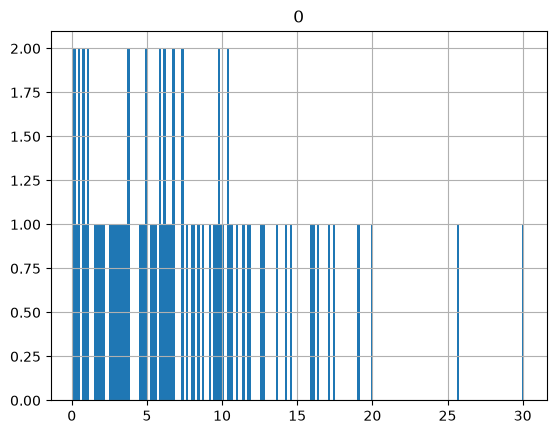

In [18]:
pd.DataFrame(df_full['avg_distance_to_health_facility_km'].unique()).hist(bins=200)

In [19]:
df_full.loc[df_full['dist_missing'] == 1, 'avg_edited'] = df_full['avg_distance_to_health_facility_km'].median()

In [20]:
# Check this later!
df_full['avg_distance_to_health_facility_km'] = df_full['avg_edited']

### Fixing data leakage here

In [21]:
months = df_full['visit_month'].unique().tolist()

split_point = int(len(months) * 0.7)

In [22]:
split_point

15

#### Calculating the MPI before splitting leakes data to the test set. Therefore, we must calculate the MPI AFTER splitting the data.
#### Because MPI is calculated individually for every village code, we must make sure that there is no 'symmetric difference' in the village codes of our training set and test set.
#### Since we are splitting on the 80% percentile of the timeline in the data, we check if all of the village codes below the split (test set) can be found in the part of the data above the split (training set).

#### It's Clean

In [23]:
len(df_full)

3676

In [24]:
# 'mpi' = village historical incidence (each village's average over its previous months)
# --- MPI from each village's PAST months only (valid for any train/test split) ---
df_full = df_full.sort_values(['village_code', 'visit_month'])
all_months = sorted(df_full['visit_month'].unique())
ref = df_full[df_full['visit_month'] < all_months[split_point]]   # training months of this split used only for scaling

components = ['incidence_per_1000', 'avg_edited', 'positivity_rate', 'spray_status']
weights = {'incidence_per_1000': 1}
village_avg = ref.groupby('village_code')[components].mean()

vals = df_full[components].copy()
for col in ['incidence_per_1000', 'positivity_rate']:
    g = df_full.groupby('village_code')[col]
    past_mean = (g.cumsum() - df_full[col]) / g.cumcount().replace(0, np.nan)
    vals[col] = past_mean.fillna(ref[col].mean())   # a village's first month: overall average

# vals['incidence_per_1000'] = np.log1p(vals['incidence_per_1000'])                 # log scaling for historical incidence

df_full['mpi'] = 0.0
for col, w in weights.items():
    lo, hi = village_avg[col].min(), village_avg[col].max()
    df_full['mpi'] += w * (vals[col] - lo) / (hi - lo)

print('Rows:', len(df_full), '| Rows without MPI:', df_full['mpi'].isna().sum())

Rows: 3676 | Rows without MPI: 0


In [25]:
#
# # --- MPI from each village's PAST months only (valid for any train/test split) ---
# # D7–D9: log-incidence, equal weights (sensitivity analysis)
# df_full = df_full.sort_values(['village_code', 'visit_month'])
# all_months = sorted(df_full['visit_month'].unique())
# ref = df_full[df_full['visit_month'] < all_months[split_point]]   # training period, only used for scaling

# components = ['incidence_per_1000', 'avg_edited', 'positivity_rate', 'spray_status']
# weights = {'incidence_per_1000': 1, 'avg_edited': 1, 'positivity_rate': 1, 'spray_status': -1}
# village_avg = ref.groupby('village_code')[components].mean()

# vals = df_full[components].copy()
# for col in ['incidence_per_1000', 'positivity_rate']:
#     g = df_full.groupby('village_code')[col]
#     past_mean = (g.cumsum() - df_full[col]) / g.cumcount().replace(0, np.nan)
#     vals[col] = past_mean.fillna(ref[col].mean())   # a village's first month: overall average

# vals['incidence_per_1000'] = np.log1p(vals['incidence_per_1000'])                 # log for D7–D9 only
# village_avg['incidence_per_1000'] = np.log1p(village_avg['incidence_per_1000'])   # log for D7–D9 only

# df_full['mpi'] = 0.0
# for col, w in weights.items():
#     lo, hi = village_avg[col].min(), village_avg[col].max()
#     df_full['mpi'] += w * (vals[col] - lo) / (hi - lo)

# print('Rows:', len(df_full), '| Rows without MPI:', df_full['mpi'].isna().sum())

#### Now, since I have programmed too deep into the model training file I think I just need to merge the training and testing set together
#### Because I have separated them at the exact same point, there shouldn't be any problems

In [26]:
final_df = df_full.copy()

In [27]:
final_df.drop(columns=['avg_edited', 'u5_incidence', 'u5_residents', 'u5_total_rdts'], inplace=True)

In [28]:
final_df = final_df.dropna()

In [29]:
len(final_df)

3676

In [30]:
final_df.to_csv('../CSVs/08_model_ready_dataset.csv')

In [31]:
final_df.isna().any().sum()

np.int64(0)

In [32]:
final_df.columns

Index(['village_code', 'visit_month', 'spray_status', 'total_residents',
       'clinic_tests', 'total_rdts', 'avg_distance_to_health_facility_km',
       'incidence_per_1000', 'positivity_rate', 'dist_missing', 'PRECTOTCORR',
       'PRECTOTCORR_SUM', 'RH2M', 'T2M', 'T2M_MAX', 'T2M_MIN', 'T2M_RANGE',
       'prev_PRECTOTCORR', 'prev2_PRECTOTCORR', 'prev3_PRECTOTCORR',
       'prev4_PRECTOTCORR', 'prev_PRECTOTCORR_SUM', 'prev2_PRECTOTCORR_SUM',
       'prev3_PRECTOTCORR_SUM', 'prev4_PRECTOTCORR_SUM', 'prev_RH2M',
       'prev2_RH2M', 'prev3_RH2M', 'prev4_RH2M', 'prev_T2M', 'prev2_T2M',
       'prev3_T2M', 'prev4_T2M', 'prev_T2M_MAX', 'prev2_T2M_MAX',
       'prev3_T2M_MAX', 'prev4_T2M_MAX', 'prev_T2M_MIN', 'prev2_T2M_MIN',
       'prev3_T2M_MIN', 'prev4_T2M_MIN', 'prev_T2M_RANGE', 'prev2_T2M_RANGE',
       'prev3_T2M_RANGE', 'prev4_T2M_RANGE', 'prev_incidence_per_1000',
       'prev_u5_incidence_per_1000', 'mpi'],
      dtype='str')

In [33]:
final_df[['village_code', 'incidence_per_1000']]

,village_code,incidence_per_1000
1,7001,61.272584
2,7001,59.701493
3,7001,25.923016
4,7001,60.487038
5,7001,45.561665
...,...,...
3954,7239,35.532995
3955,7239,55.837563
3956,7239,91.370558
3957,7239,48.223350


In [34]:
village_incidences = []
for village in final_df['village_code'].unique():
    village_incidences.append(\
        np.mean(final_df[final_df['village_code'] == village]['incidence_per_1000']))

In [35]:
pd.DataFrame(village_incidences).describe()

,0
count,185.000000
mean,38.915865
std,34.776978
min,0.845829
25%,17.619189
50%,30.936744
75%,49.605411
max,255.555556


In [36]:
final_df.columns

Index(['village_code', 'visit_month', 'spray_status', 'total_residents',
       'clinic_tests', 'total_rdts', 'avg_distance_to_health_facility_km',
       'incidence_per_1000', 'positivity_rate', 'dist_missing', 'PRECTOTCORR',
       'PRECTOTCORR_SUM', 'RH2M', 'T2M', 'T2M_MAX', 'T2M_MIN', 'T2M_RANGE',
       'prev_PRECTOTCORR', 'prev2_PRECTOTCORR', 'prev3_PRECTOTCORR',
       'prev4_PRECTOTCORR', 'prev_PRECTOTCORR_SUM', 'prev2_PRECTOTCORR_SUM',
       'prev3_PRECTOTCORR_SUM', 'prev4_PRECTOTCORR_SUM', 'prev_RH2M',
       'prev2_RH2M', 'prev3_RH2M', 'prev4_RH2M', 'prev_T2M', 'prev2_T2M',
       'prev3_T2M', 'prev4_T2M', 'prev_T2M_MAX', 'prev2_T2M_MAX',
       'prev3_T2M_MAX', 'prev4_T2M_MAX', 'prev_T2M_MIN', 'prev2_T2M_MIN',
       'prev3_T2M_MIN', 'prev4_T2M_MIN', 'prev_T2M_RANGE', 'prev2_T2M_RANGE',
       'prev3_T2M_RANGE', 'prev4_T2M_RANGE', 'prev_incidence_per_1000',
       'prev_u5_incidence_per_1000', 'mpi'],
      dtype='str')

In [46]:
final_df[final_df['dist_missing'] == 1]['incidence_per_1000'].mean(), \
final_df[final_df['dist_missing'] == 0]['incidence_per_1000'].mean()

(np.float64(46.42754941774553), np.float64(37.508134908957864))